In [138]:
# Collect the data
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Path to dataset files: /home/sudipto/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1


In [139]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


In [140]:

DATASET_PATH = os.path.join(path, 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

df = pd.read_csv(DATASET_PATH)

In [141]:

ROOT_DIR = os.path.dirname(os.getcwd())

DATA_DIR = os.path.join(ROOT_DIR, 'data')
DATA_DIR_RAW = os.path.join(DATA_DIR, 'raw')
DATA_DIR_PROCESSED = os.path.join(DATA_DIR, 'processed')

DATASET_NAME_V1 = f"{DATA_DIR_RAW}/churnv1.csv"



#### Load the dataset

In [142]:
df = pd.read_csv(DATASET_NAME_V1)
df.drop(columns=['Unnamed: 0'], inplace=True)
df.sample(5)

,index,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1173,1173,0107-WESLM,Male,0,No,No,1,Yes,No,No,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,19.85,19.85,Yes
6073,6073,6096-EGVTU,Female,0,Yes,Yes,64,Yes,Yes,No,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,24.90,1595.5,No
4099,4099,6624-JDRDS,Female,0,No,No,6,No,No phone service,DSL,...,No,No,No,No,Month-to-month,No,Bank transfer (automatic),29.45,161.45,No
5334,5334,6386-SZZKH,Female,0,Yes,Yes,49,Yes,Yes,Fiber optic,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),107.95,5293.2,Yes
6652,6652,0827-ITJPH,Male,0,No,No,36,Yes,No,No,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),18.55,689,No


#### Dataset info

In [143]:
# df = df.rename(columns={'Inedx': 'Index'})
# df.drop(columns=['Unnamed: 0'], inplace=True)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             7043 non-null   int64  
 1   customerID        7043 non-null   object 
 2   gender            7043 non-null   object 
 3   SeniorCitizen     7043 non-null   int64  
 4   Partner           7043 non-null   object 
 5   Dependents        7043 non-null   object 
 6   tenure            7043 non-null   int64  
 7   PhoneService      7043 non-null   object 
 8   MultipleLines     7043 non-null   object 
 9   InternetService   7043 non-null   object 
 10  OnlineSecurity    7043 non-null   object 
 11  OnlineBackup      7043 non-null   object 
 12  DeviceProtection  7043 non-null   object 
 13  TechSupport       7043 non-null   object 
 14  StreamingTV       7043 non-null   object 
 15  StreamingMovies   7043 non-null   object 
 16  Contract          7043 non-null   object 


### Data Exploration

### Target 

__Churn__ Column is our target column and here we need to find the customer/individual who can leave service within a specific period of time.

>__Churn prediction is the use of data, statistics, and machine learning to forecast which customers or subscribers are likely to stop using a product or cancel a service within a specific time frame__

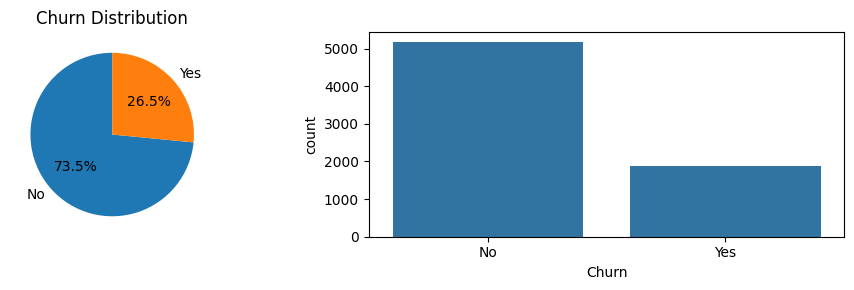

In [144]:
churn_counts = df['Churn'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].pie(churn_counts, 
            labels=churn_counts.index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0].set_title('Churn Distribution')

sns.countplot(data=df, x='Churn', ax=axes[1])
fig.tight_layout()
plt.show()

In [191]:
print(f"Null values: \n{df.isna().sum()}")

Null values: 
index               0
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


__Separate Feature and target columns from the dataset__

In [145]:
features = df.drop(columns=['Churn', 'index', 'customerID'])
target = df['Churn']

__Gender:__ Whether the customer is a male or a female

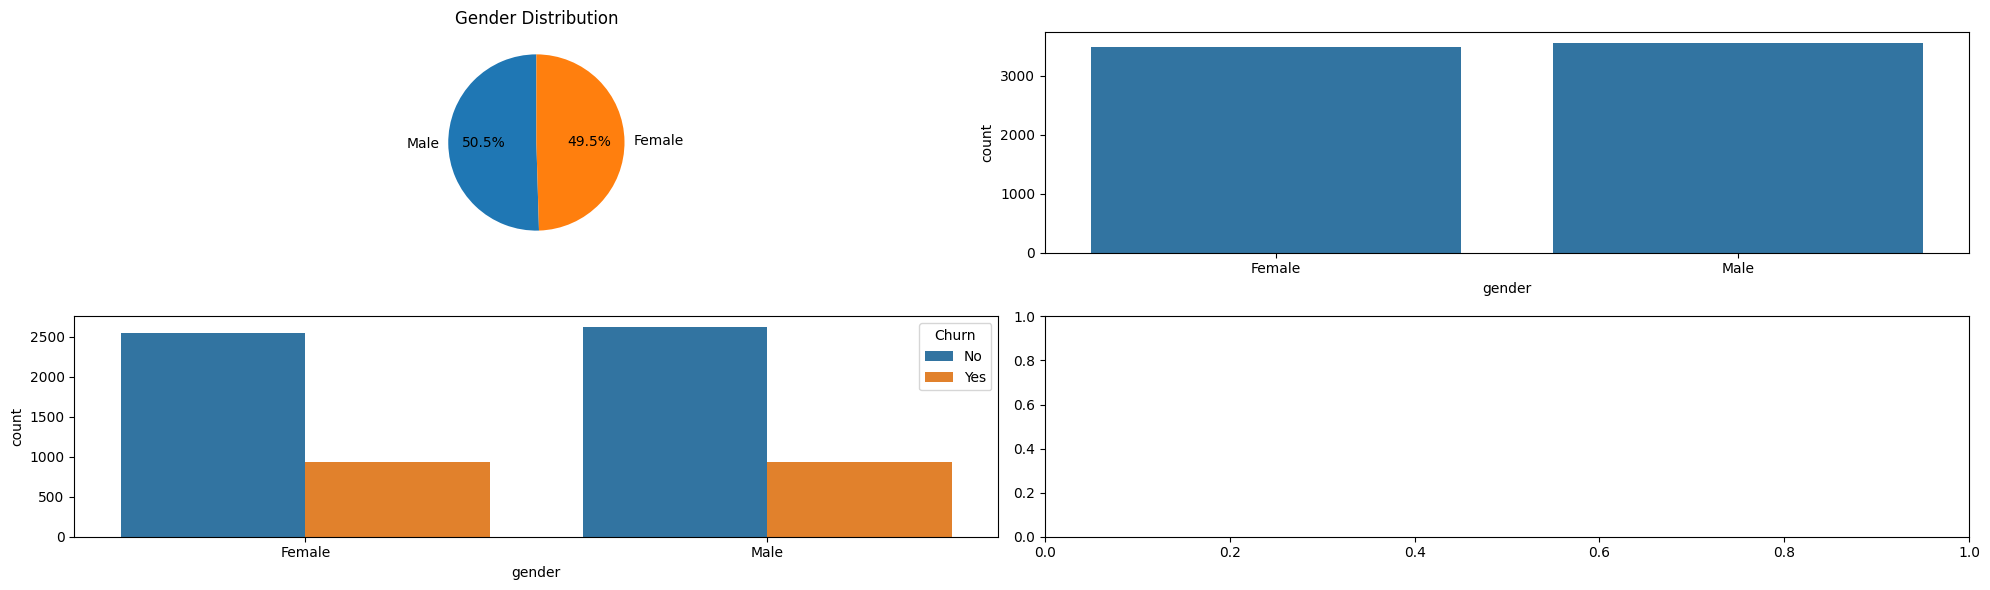

In [146]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['gender'].value_counts(), 
            labels=features['gender'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Gender Distribution')

sns.countplot(data=features, x='gender', ax=axes[0, 1])
sns.countplot(data=features, x='gender', hue=target, ax=axes[1, 0])

fig.tight_layout()

plt.show()

__We have 50.5% of male and 49.5% of female here and in counts there are 3555 male and 3488 female customers.__

In [147]:
print(features['SeniorCitizen'].value_counts())

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In `SeniorCitizen` columns we have only value 0 and 1. That means `boolean` value is that this __individual__ is __SeniorCitizen__ or not.

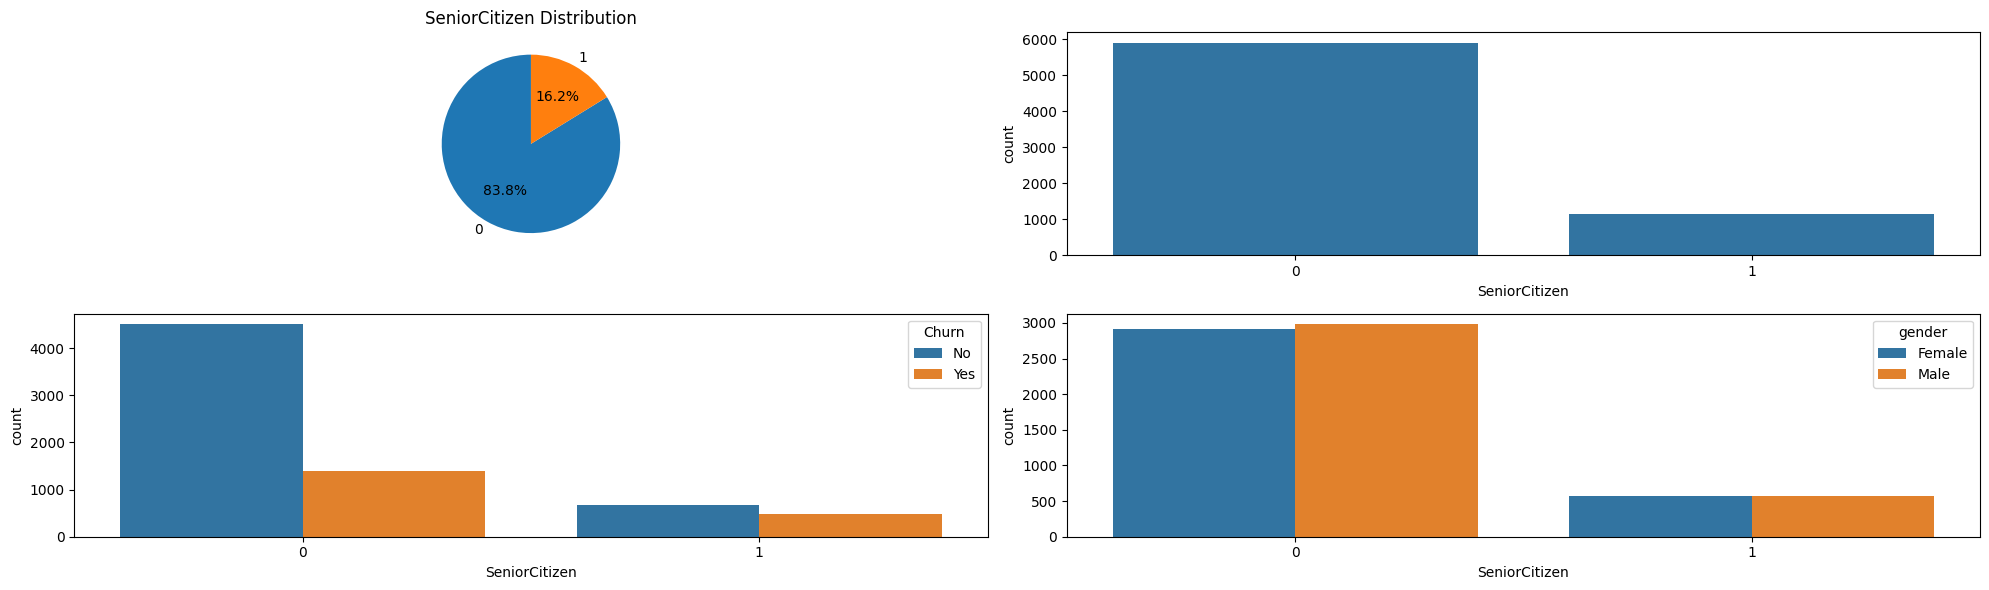

In [148]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['SeniorCitizen'].value_counts(), 
            labels=features['SeniorCitizen'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('SeniorCitizen Distribution')

sns.countplot(data=features, x='SeniorCitizen', ax=axes[0, 1])
sns.countplot(data=features, x='SeniorCitizen', hue=target, ax=axes[1, 0])
sns.countplot(data=features, x='SeniorCitizen', hue='gender', ax=axes[1, 1])


fig.tight_layout()

plt.show()

__Partner:__ Whether the customer has a partner or not (Yes, No)

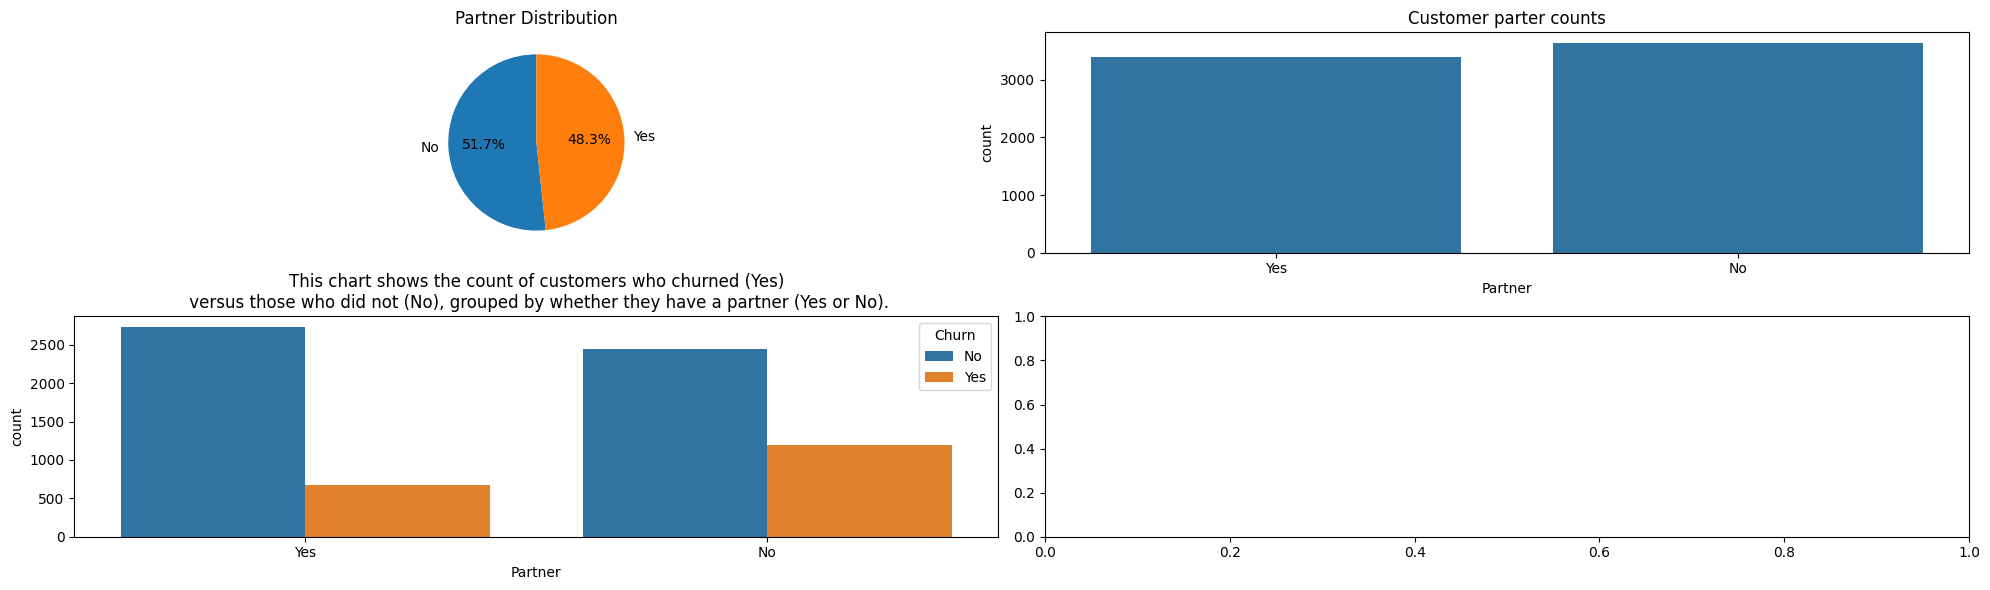

In [150]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['Partner'].value_counts(), 
            labels=features['Partner'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('Partner Distribution')

sns.countplot(data=features, x='Partner', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='Partner', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart shows the count of customers who churned (Yes)\n versus those who did not (No), grouped by whether they have a partner (Yes or No).')
fig.tight_layout()

plt.show()

In dataset there are 48.3% of individual who have __parterns__ and 51.7% who dont have __Parterns__

Customers with a __Partner__ (Yes on the left): Roughly 2,700 stayed (Churn = No), while around 650 churned (Churn = Yes) - a relatively low churn rate.
Customers without a __Partner__ (No on the right): Roughly 2,400 stayed (Churn = No), while about 1,200 churned (Churn = Yes) — nearly double the number of churns compared to customers with partners.

<br><br>
__Dependents:__ Whether the customer has dependents or not (Yes, No).
It indicates whether the customer lives with any family members who rely on them, such as children, parents, or grandparents.

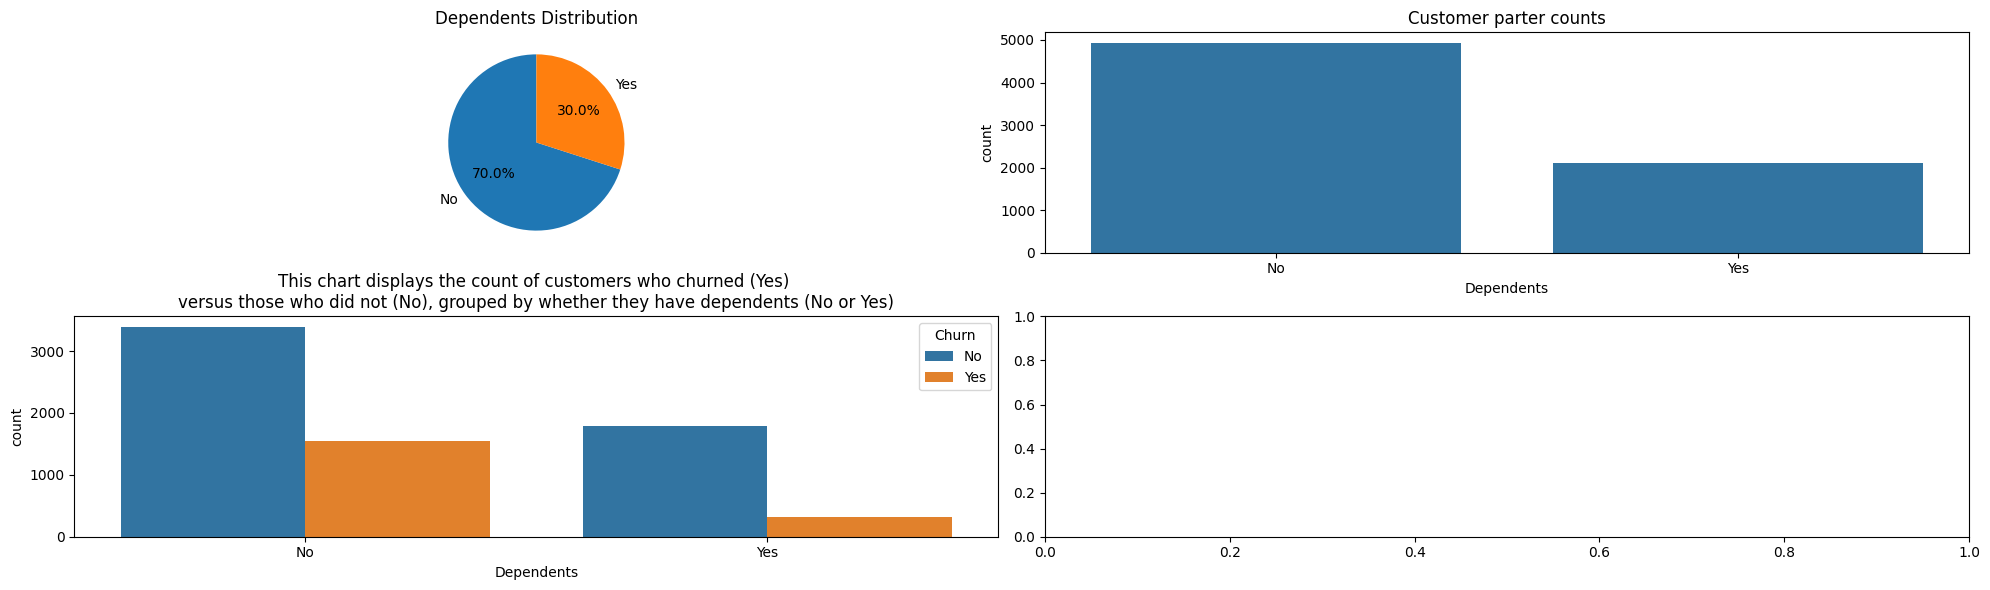

In [151]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['Dependents'].value_counts(),
    labels=features['Dependents'].value_counts().index,
    autopct='%1.1f%%',
    startangle=90)

axes[0, 0].set_title('Dependents Distribution')
sns.countplot(data=features, x='Dependents', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='Dependents', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have dependents (No or Yes)')

fig.tight_layout()
plt.show()

In dataset there are 30% of individual who have __Dependents__ and 70% of individual who dont have any __Dependents__

1. Customers without __Dependents__ (No on the left): This is the largest group overall. Roughly 3,400 customers stayed (Churn = No), while over 1,500 churned (Churn = Yes), representing a high churn count and rate.
2. Customers with __Dependents__ (Yes on the right): Fewer customers in the dataset have dependents. Around 1,800 stayed (Churn = No), while only about 300 churned (Churn = Yes), showing a significantly lower churn rate compared to those without dependents.

<br><br>
__Tenure:__ Number of months the customer has stayed with the company

In [193]:
tenure_zero_index = features[features['tenure'] == 0].index
print(f'We have total {len(tenure_zero_index)} very new customers who doesnt yet complete the one 1 biling cycle.')

We have total 11 very new customers who doesnt yet complete the one 1 biling cycle.


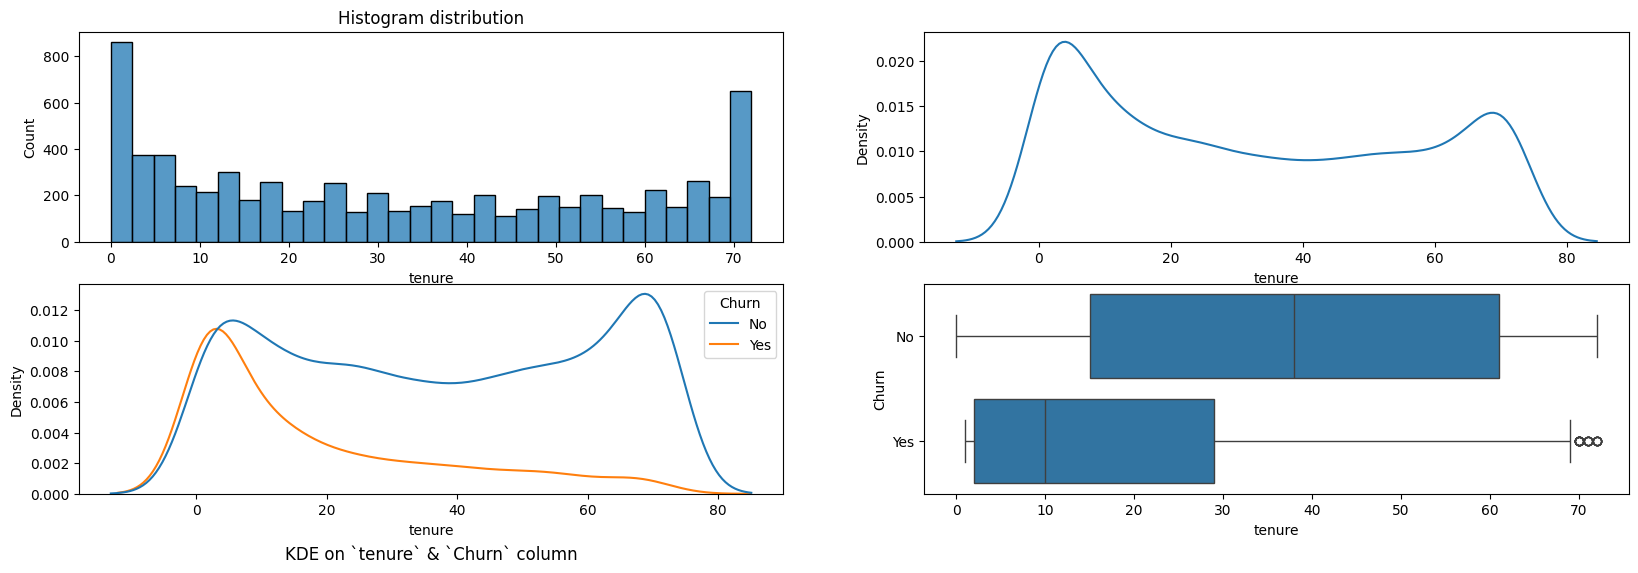

In [152]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

sns.histplot(data=features, x='tenure', bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Histogram distribution')

sns.kdeplot(data=features, x='tenure', ax=axes[0, 1])
axes[0, 0].set_title('Histogram distribution')

sns.kdeplot(data=features, x='tenure', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('KDE on `tenure` & `Churn` column', y=-0.35)

sns.boxplot(data=features, x='tenure', y=target, ax=axes[1, 1])

plt.show()

Histogram displays the row count of customers across different tenure lengths. It highlights a bimodal(2 peak) pattern:
1. __New customers:__ There is a massive spike at the very begining 0-3 months, meaning the company accquires a high volume of new customers.
2. __Loyal customers:__ There is a second major peak near the 70-month mark, showing that a large group of customers stays with the company for a very long time

<br>

__KDE with `tenure` and `Churn` column__
* __High churn at lower tenure(New customers):__ The orange line (churn = yes) has a steep peak at the very begining (between 0 and 10 months). This indicates that new customers are much more likely to churn early on.

* __Lower Tenure equal higher retension:__ The blue line (Churn = No) stays prominent across all tenures and shows a major peak around 70 months. This means customers who stick around for a long time are significantly less likely to churn

__PhoneService:__ Whether the customer has a phone service or not (Yes, No)

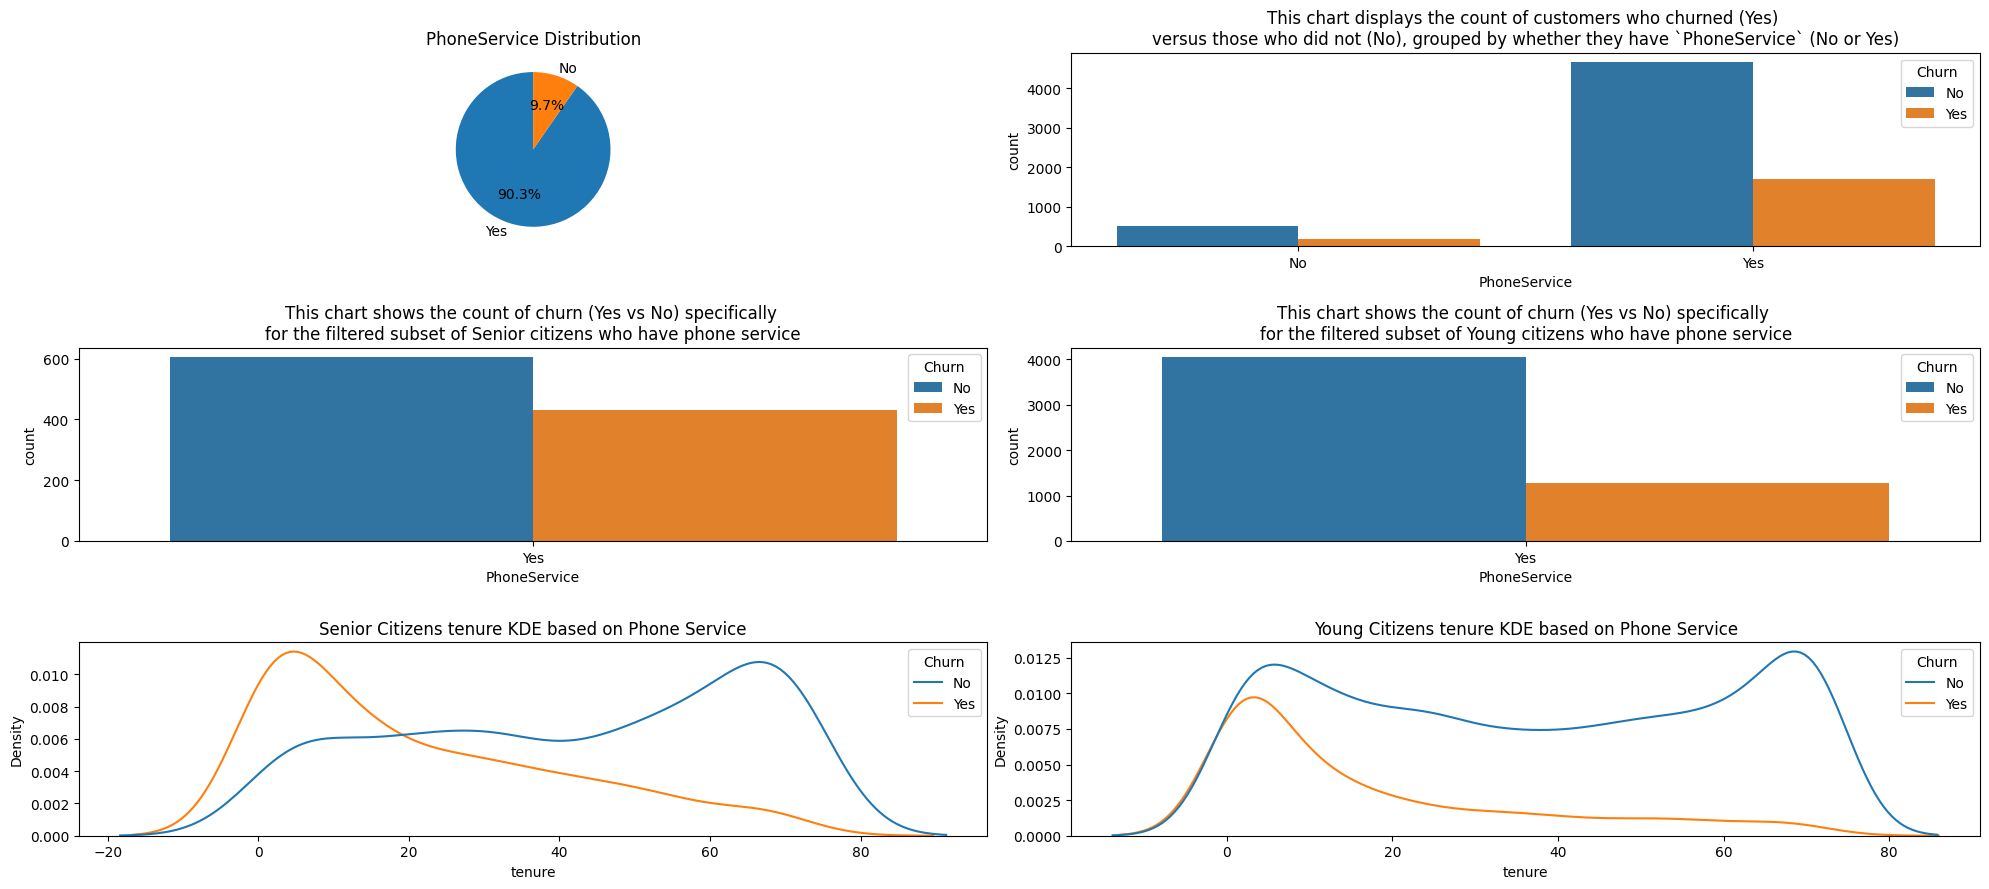

In [153]:
senior_citizen_who_get_phone_service_df = features[(features['PhoneService'] == 'Yes') & (features['SeniorCitizen'] == 1)]
young_citizen_who_get_phone_service_df = features[(features['PhoneService'] == 'Yes') & (features['SeniorCitizen'] == 0)]

fig, axes = plt.subplots(3, 2, figsize=(20, 9))

axes[0, 0].pie(features['PhoneService'].value_counts(), 
            labels=features['PhoneService'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('PhoneService Distribution')

# sns.countplot(data=features, x='PhoneService', ax=axes[0, 1])
# axes[0, 1].set_title('Customer PhoneService counts')

sns.countplot(data=features, x='PhoneService', hue=target, ax=axes[0, 1])
axes[0, 1].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have `PhoneService` (No or Yes)')

sns.countplot(data=senior_citizen_who_get_phone_service_df, x='PhoneService', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Senior citizens who have phone service')

sns.countplot(data=young_citizen_who_get_phone_service_df, x='PhoneService', hue=target, ax=axes[1, 1])
axes[1, 1].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Young citizens who have phone service')

sns.kdeplot(data=senior_citizen_who_get_phone_service_df, x='tenure', hue=target, ax=axes[2, 0])
axes[2, 0].set_title('Senior Citizens tenure KDE based on Phone Service')

sns.kdeplot(data=young_citizen_who_get_phone_service_df, x='tenure', hue=target, ax=axes[2, 1])
axes[2, 1].set_title('Young Citizens tenure KDE based on Phone Service')

fig.tight_layout()
plt.show()

* __Customers with Phone Service (Yes):__ This represents the overwhelming majority of the customer base. Roughly 4600 customer stayed (Churn = No), While about 1700 churned or (Churn = Yes)

* __Customers with Phone Service (No):__ This is very small portion of the data. Around 500 customers stayed (Churn = No) while roughly 200 individual churned (Churn = Yes)

__MultipleLines:__ Whether the customer has multiple lines or not (Yes, No, No phone service)

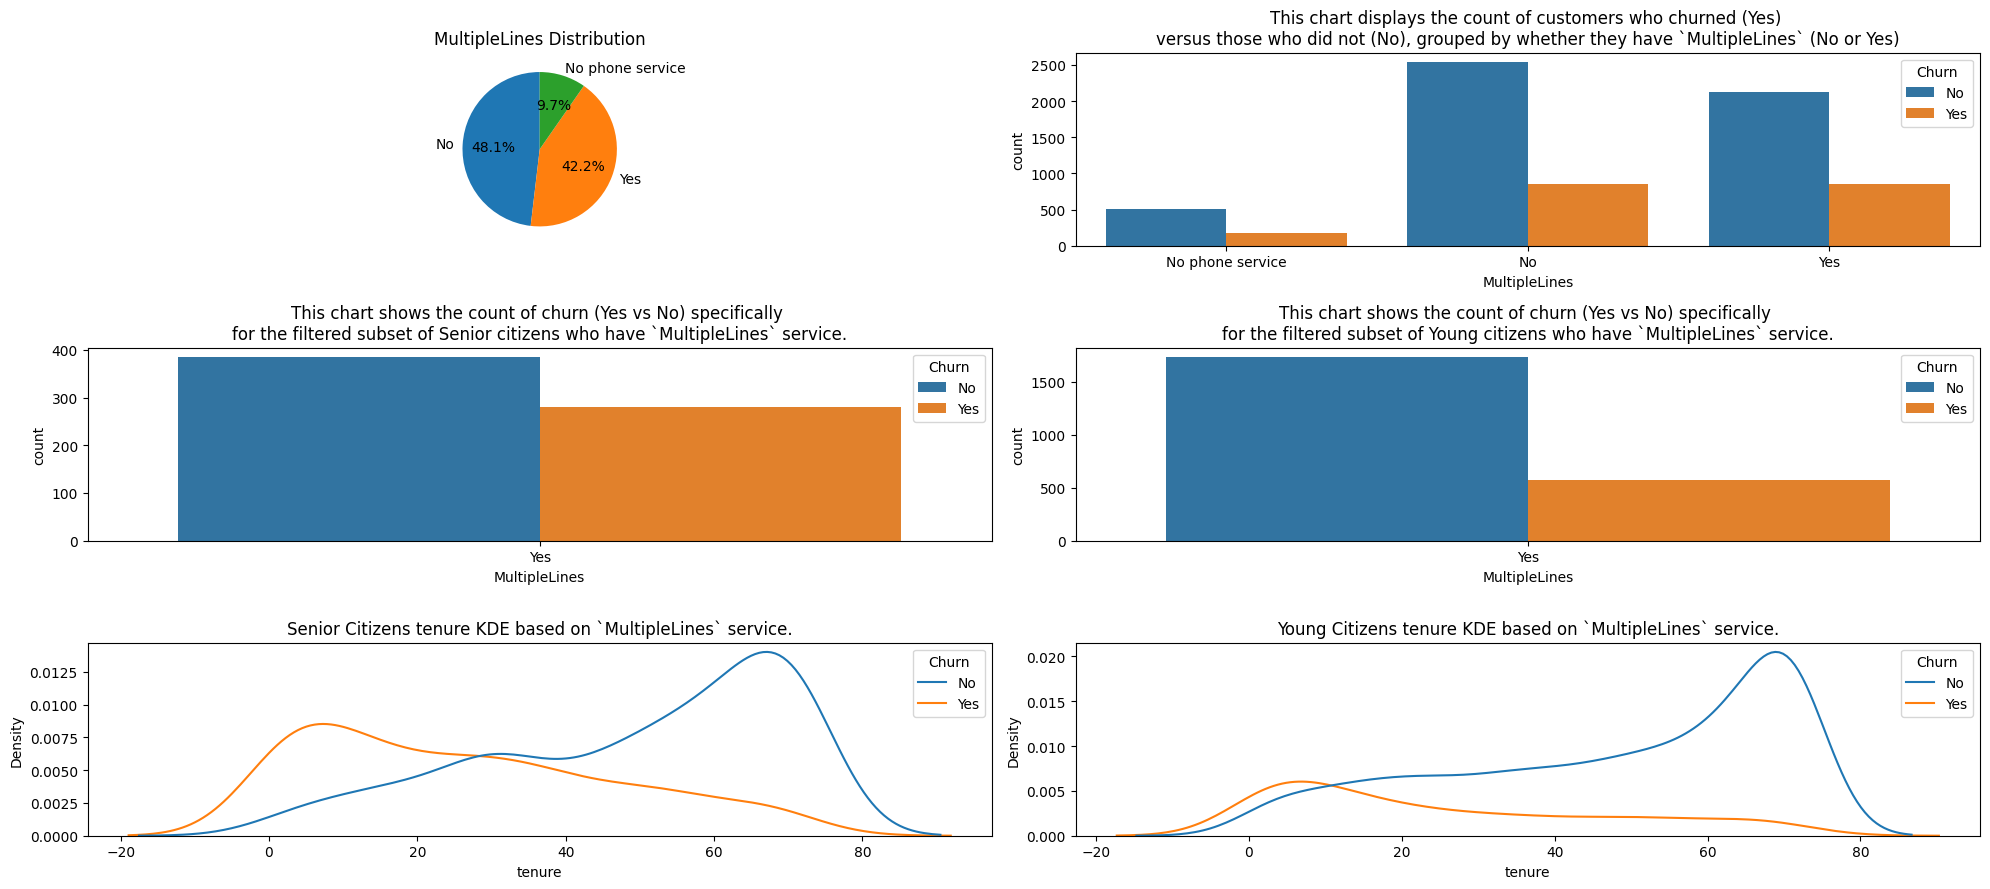

In [154]:
senior_citizen_who_get_multiple_lines_df = features[(features['MultipleLines'] == 'Yes') & (features['SeniorCitizen'] == 1)]
young_citizen_who_get_multiple_lines_df = features[(features['MultipleLines'] == 'Yes') & (features['SeniorCitizen'] == 0)]

fig, axes = plt.subplots(3, 2, figsize=(20, 9))

axes[0, 0].pie(features['MultipleLines'].value_counts(), 
            labels=features['MultipleLines'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('MultipleLines Distribution')

sns.countplot(data=features, x='MultipleLines', hue=target, ax=axes[0, 1])
axes[0, 1].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by whether they have `MultipleLines` (No or Yes)')

sns.countplot(data=senior_citizen_who_get_multiple_lines_df, x='MultipleLines', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Senior citizens who have `MultipleLines` service.')

sns.countplot(data=young_citizen_who_get_multiple_lines_df, x='MultipleLines', hue=target, ax=axes[1, 1])
axes[1, 1].set_title('This chart shows the count of churn (Yes vs No) specifically \nfor the filtered subset of Young citizens who have `MultipleLines` service.')

sns.kdeplot(data=senior_citizen_who_get_multiple_lines_df, x='tenure', hue=target, ax=axes[2, 0])
axes[2, 0].set_title('Senior Citizens tenure KDE based on `MultipleLines` service.')

sns.kdeplot(data=young_citizen_who_get_multiple_lines_df, x='tenure', hue=target, ax=axes[2, 1])
axes[2, 1].set_title('Young Citizens tenure KDE based on `MultipleLines` service.')

fig.tight_layout()
plt.show()

* __No phone service:__ A small group of about 500 customer stayed Churn = No, while roughly 200 individuals are churned.
* __No Multiple Lines:__ This is the largest segment, around 2500 plus customers stayed Churn = No, while about 800 plus are churned (Churn = Yes)
* __Yes Multiple Lines:__ Roughly 2100 plus customers stayed churn = no and about 800 plus individuals are churned. The actual number pf customers who churned is identical to the "No" group, though the retention count is slightly low.

In KDE plot there is a clear peak at a low tenure (5~10) months indicating that individual(Senior/Young) who decide to leave(Churn = Yes) tend to do so early in their customer lifecycle and the blue line features a sharp dominant peak near (65~70) months, showing that senior citizens who stick with the company fo a long time are far less likely to churn

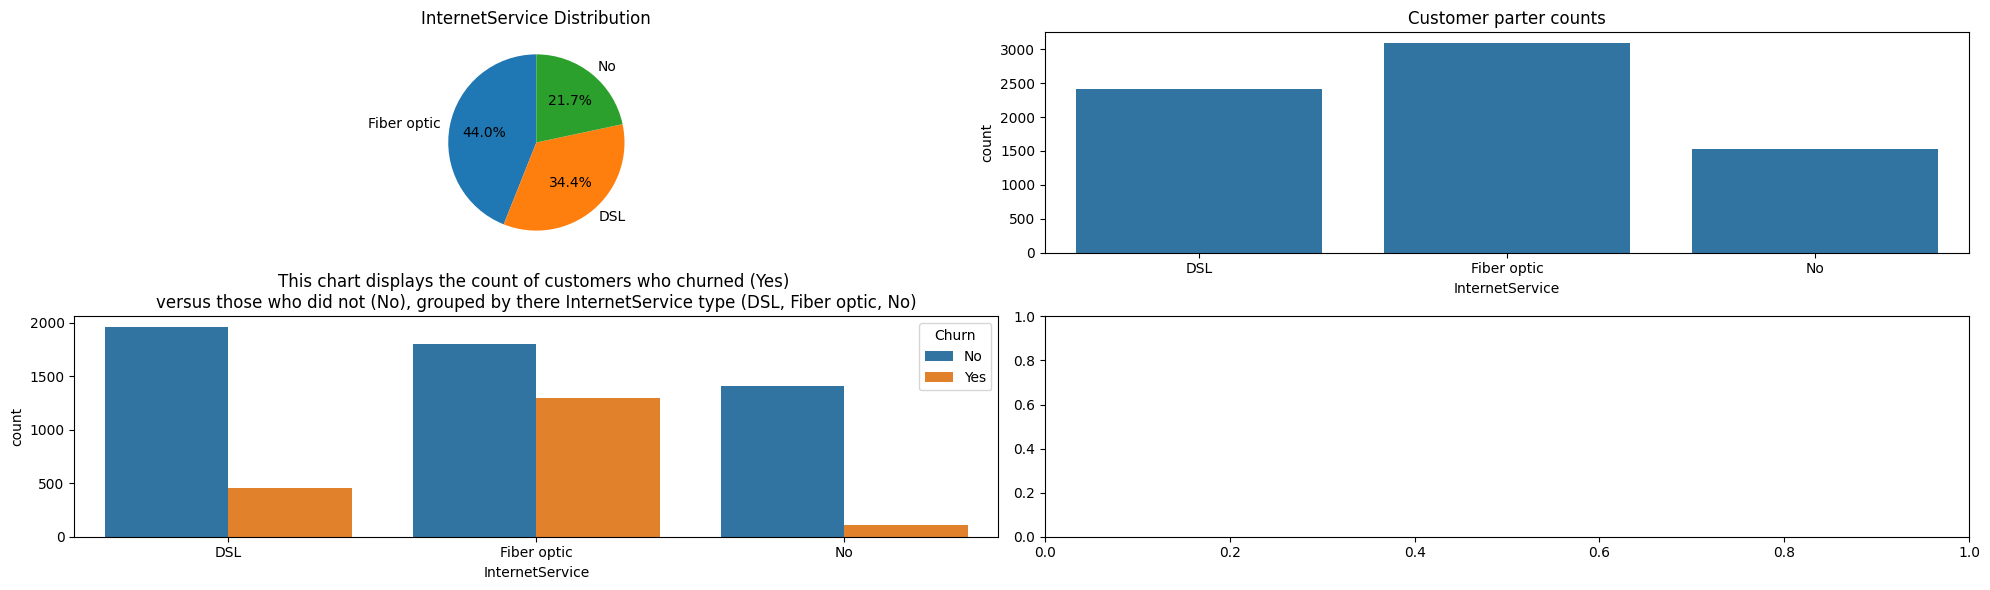

In [155]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['InternetService'].value_counts(), 
            labels=features['InternetService'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('InternetService Distribution')

sns.countplot(data=features, x='InternetService', ax=axes[0, 1])
axes[0, 1].set_title('Customer parter counts')

sns.countplot(data=features, x='InternetService', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by there InternetService type (DSL, Fiber optic, No)')

fig.tight_layout()
plt.show()

* __DSL:__ Around 1900~2000 customers stayed (Churn = No), while roughly 400 churned (Churn = Yes), indicating a relatively low churn rate among DSL users.

* __Fiber optic:__ Around 1700-1800 customers are stayed, while around 1300-1400 customers are chruned. The group has both highest number of chruned customers and noticeble high churn rate compared to other categories.

* __No internet service:__ About 1300-1400 customers stayed and only around 100 customers are chruned which make this segment with the lowest churn

Customers who takes the `OnlineSecurity` service.

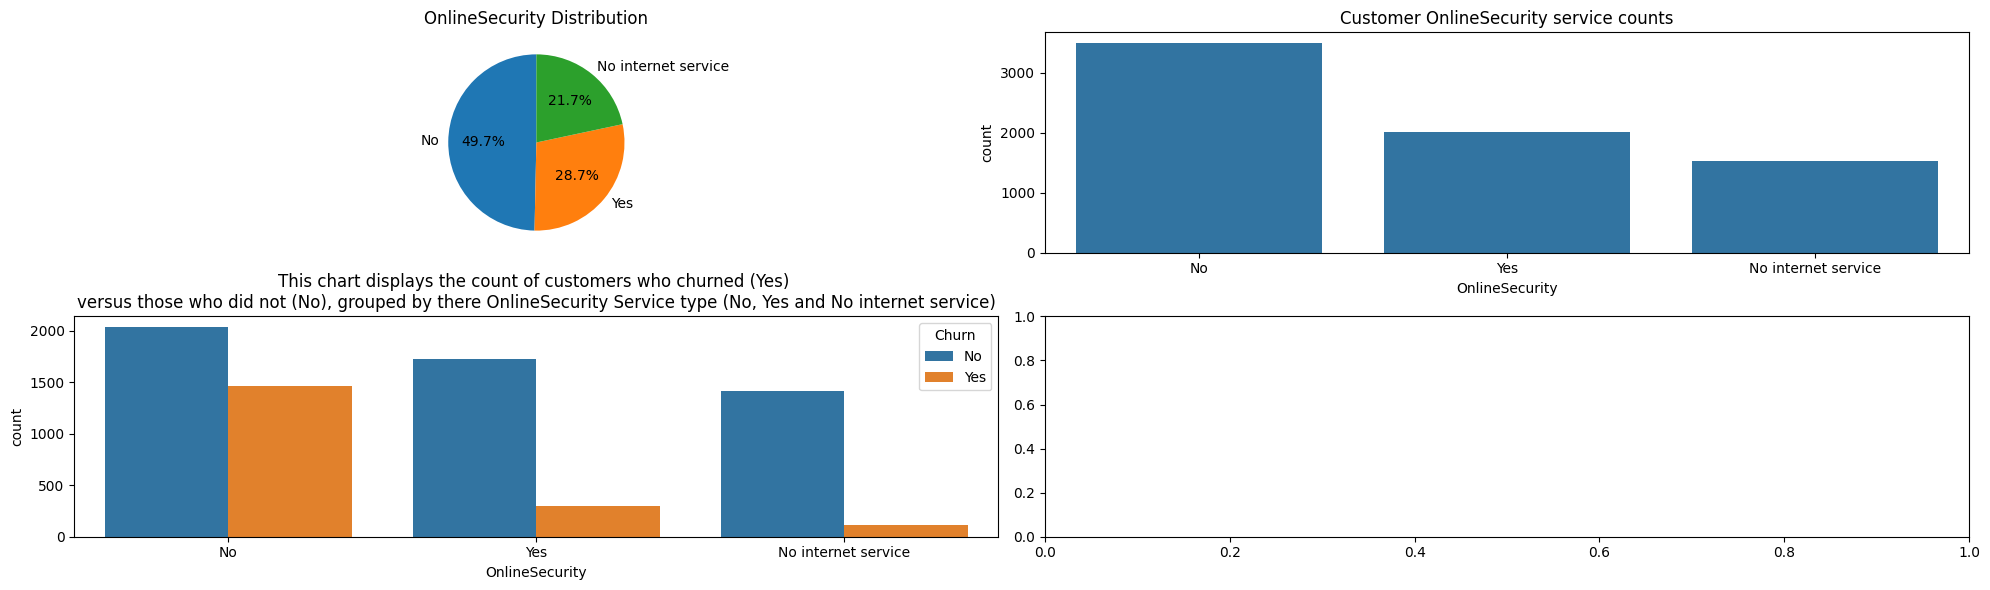

In [156]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['OnlineSecurity'].value_counts(), 
            labels=features['OnlineSecurity'].value_counts().index, 
            autopct='%1.1f%%', 
            startangle=90)
axes[0, 0].set_title('OnlineSecurity Distribution')

sns.countplot(data=features, x='OnlineSecurity', ax=axes[0, 1])
axes[0, 1].set_title('Customer OnlineSecurity service counts')

sns.countplot(data=features, x='OnlineSecurity', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by there OnlineSecurity Service type (No, Yes and No internet service)')

fig.tight_layout()
plt.show()

`OnlineSecurity` Whether the customer has online security or not (`Yes`, `No`, `No internet service`)
We can see that majority of the individuals not take the `OnlineSecurity` service which is __49.7%__ and we can see that they have higher rate of `Churn`, who take take the `OnlineSecurity` service. And those who take `no internet service` they have very lower rate of `Churn`.

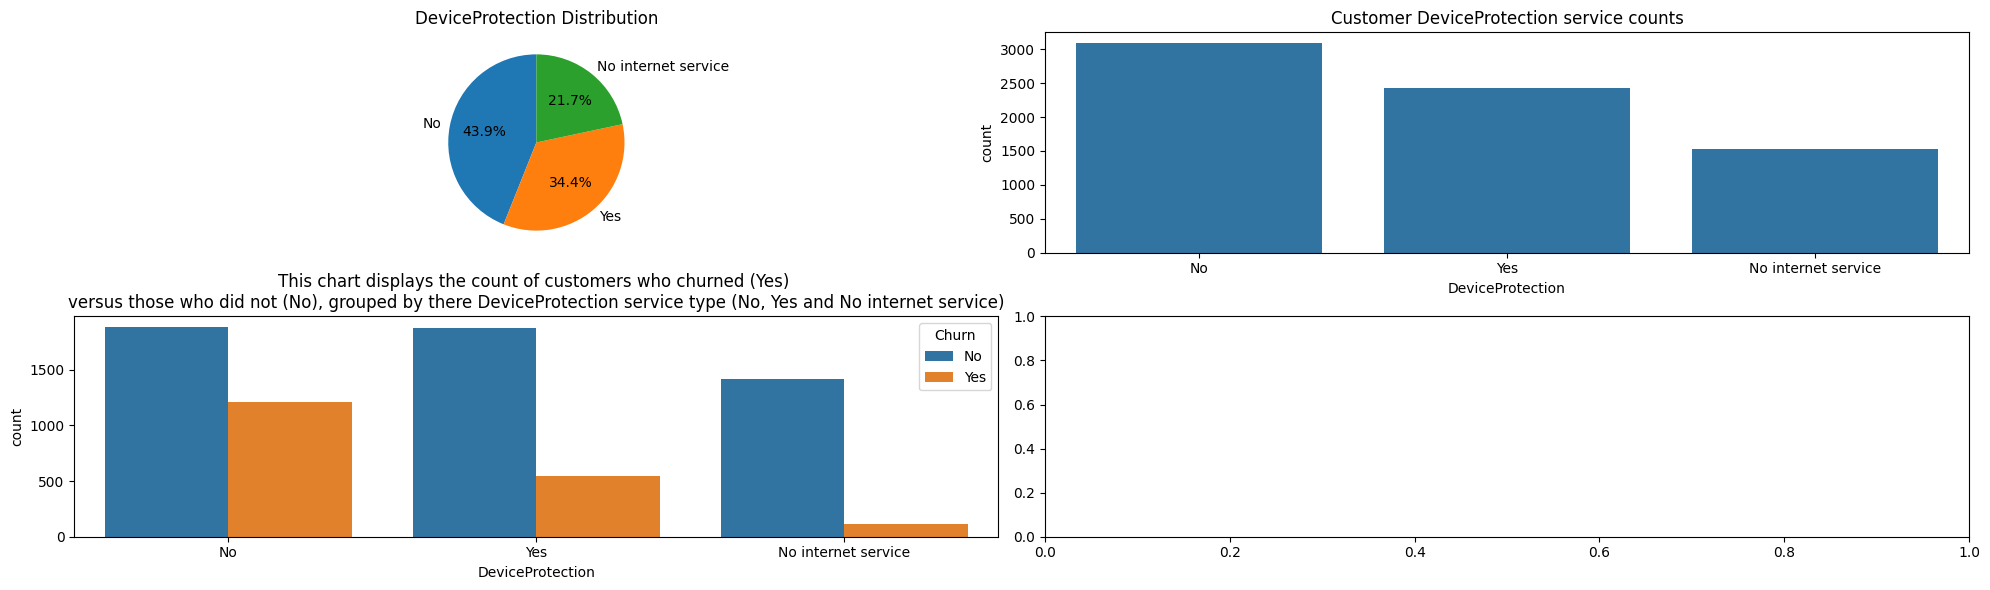

In [157]:

fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['DeviceProtection'].value_counts(), 
    labels=features['DeviceProtection'].value_counts().index, 
    autopct='%1.1f%%',
    startangle=90)
axes[0, 0].set_title('DeviceProtection Distribution')

sns.countplot(data=features, x='DeviceProtection', ax=axes[0, 1])
axes[0, 1].set_title('Customer DeviceProtection service counts')

sns.countplot(data=features, x='DeviceProtection', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) \nversus those who did not (No), grouped by there DeviceProtection service type (No, Yes and No internet service)')

fig.tight_layout()
plt.show()

Above from this charts we can see that __No__ is total __43.9%__, __Yes__ is __34.4%__ and __21.7%__ have __No internet service__.

* __No:__ Around 1800 customers who take No device protection service they stayed and around 1220 or 1230 customer they churned. In this category has higher rate of Churn and No Churn among other cateogries.

* __Yes:__ In this section we also have around 1700-1800 customer who take the service, which shows the higher rate that customer stayed (Churn = No) and around 600 customer who are Churned.

* __No internet service:__ About 1350-1400 customers who have no interner service are stayed while only 100 customers who Churned.

In [158]:
features['DeviceProtection'].value_counts()

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

* __No (Device Protection):__ Roughly 1800 plus customers did not churn, while approximately 1200 customers churned representing the highest volume and proportion of churn among the three groups.
* __Yes (Device Protection):__ Roughly 1800 plus customers did not churn (nearly identical to the "No" group), but churn dropped significantly to around 500 plus customers.
* __No internet service:__ Roughly 1400 plus customers did not churn, while very few around 100~120 customers churned.

Customers with internet service who lack device protection churn at a noticeably higher rate than those who have device protection or do not subscribe to internet service at all.

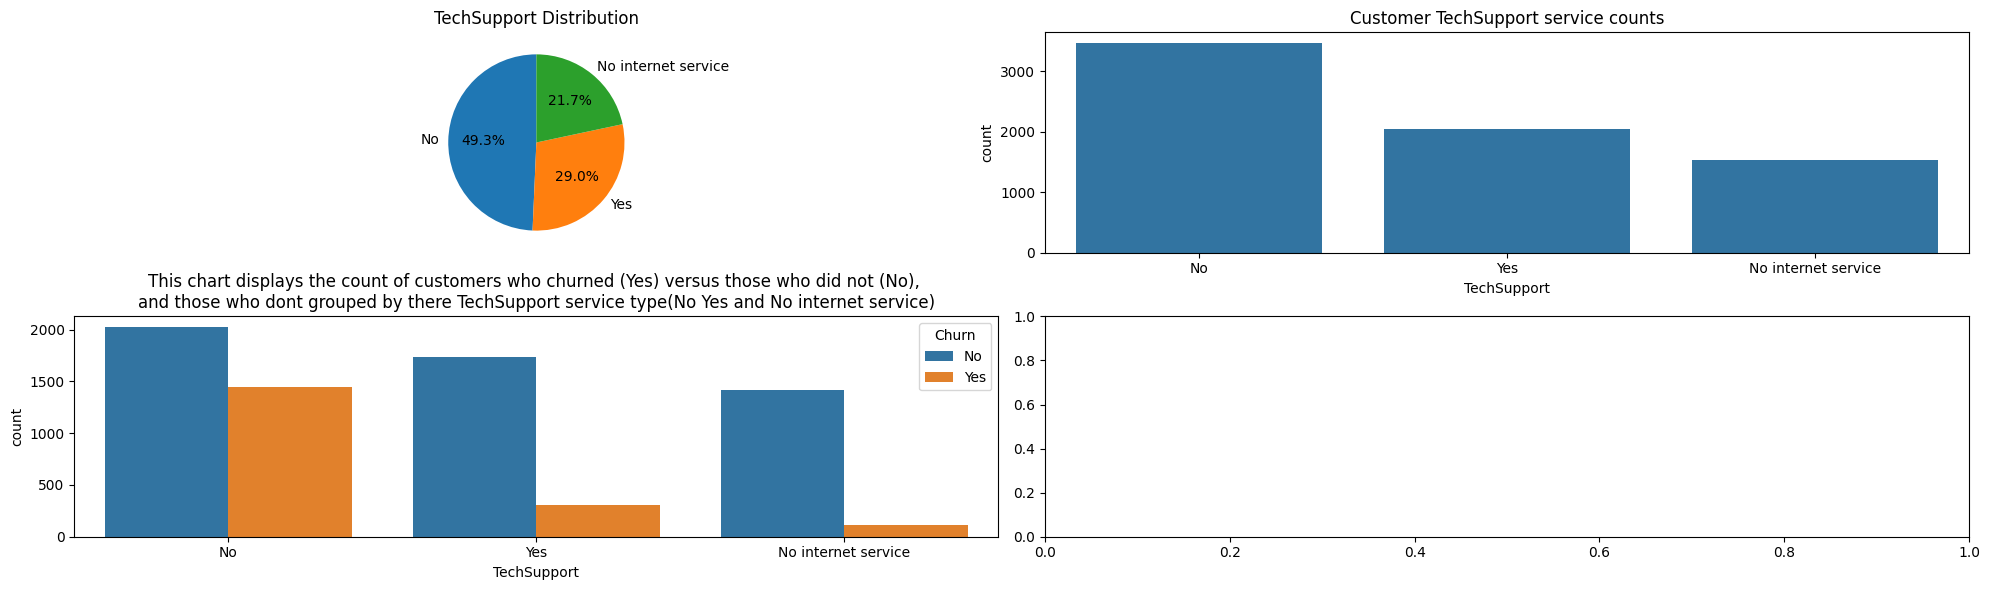

In [159]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['TechSupport'].value_counts(), 
    labels=features['TechSupport'].value_counts().index, 
    autopct='%1.1f%%', 
    startangle=90)
axes[0, 0].set_title('TechSupport Distribution')

sns.countplot(data=features, x='TechSupport', ax=axes[0, 1])
axes[0, 1].set_title('Customer TechSupport service counts')

sns.countplot(data=features, x='TechSupport', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) versus those who did not (No), \nand those who dont grouped by there TechSupport service type(No Yes and No internet service)')

fig.tight_layout()
plt.show()

Customer who take the`StreamingTV` service

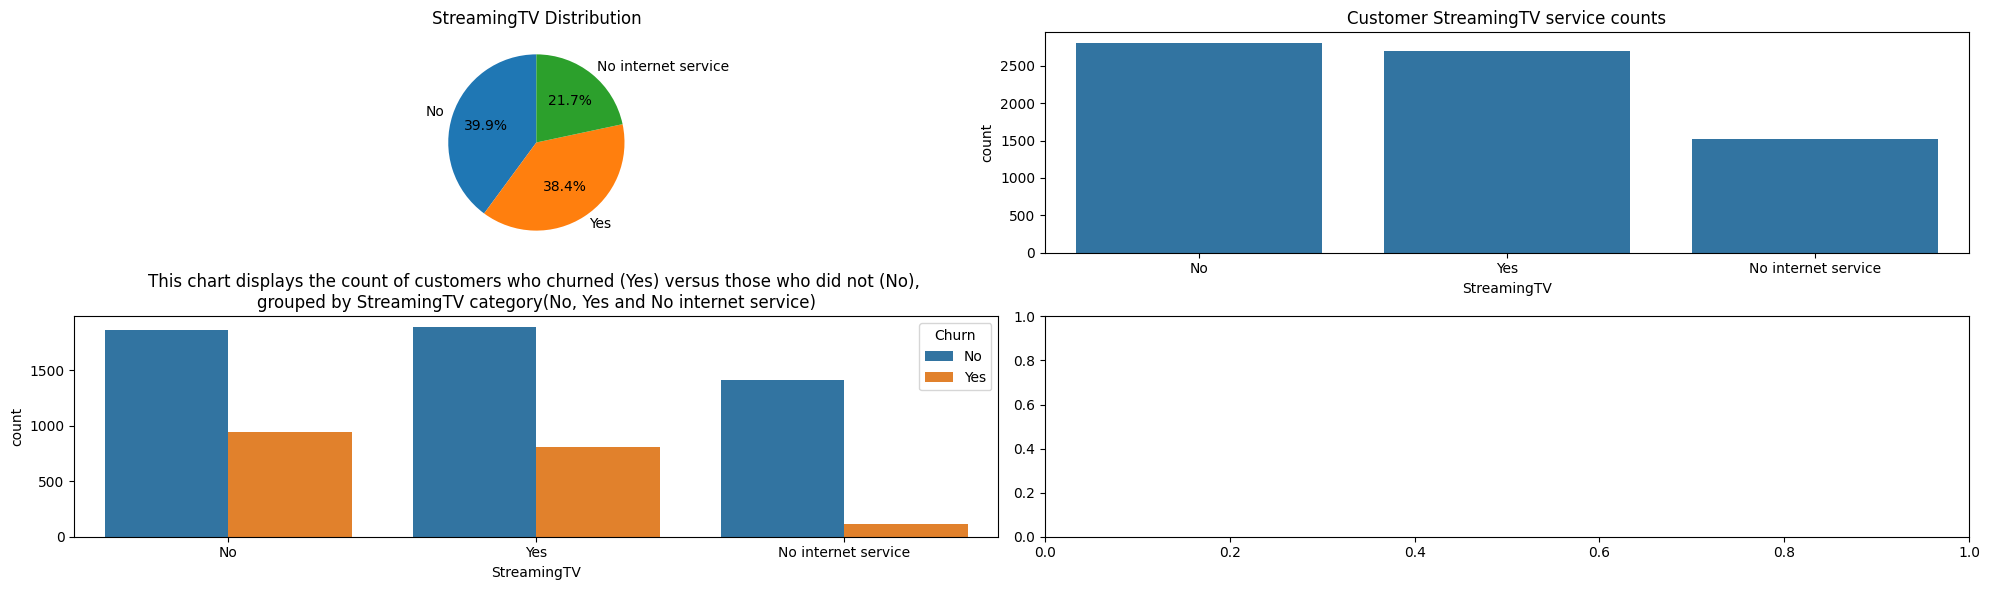

In [160]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['StreamingTV'].value_counts(), 
    labels=features['StreamingTV'].value_counts().index, 
    autopct='%1.1f%%', 
    startangle=90)
axes[0, 0].set_title('StreamingTV Distribution')

sns.countplot(data=features, x='StreamingTV', ax=axes[0, 1])
axes[0, 1].set_title('Customer StreamingTV service counts')

sns.countplot(data=features, x='StreamingTV', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) versus those who did not (No), \ngrouped by StreamingTV category(No, Yes and No internet service)')

fig.tight_layout()
plt.show()

From above charts we can see that Customer who take the `StreamingTV` services are `38.4%` No is `39.9%` and customer who dont take the internet service is `21.7%`.
When we compare it with Customer is Churned or not based on the category:
* __No:__ Around 1800 customers who are stayed (Churn = No) and around 800-900 customers are Churned (Churn = Yes).
* __Yes:__ Around 1850-1900 customer are stayed (Churn = No) and around 800-850 customers are Churned (Churn = Yes).
* __No internet service:__ Approximately 1,400 stayed and only around 100 churned, demonstrating the lowest churn rate among the three groups.


<br/><br/>
Wheather a customer take `StreamingMovies` service or not

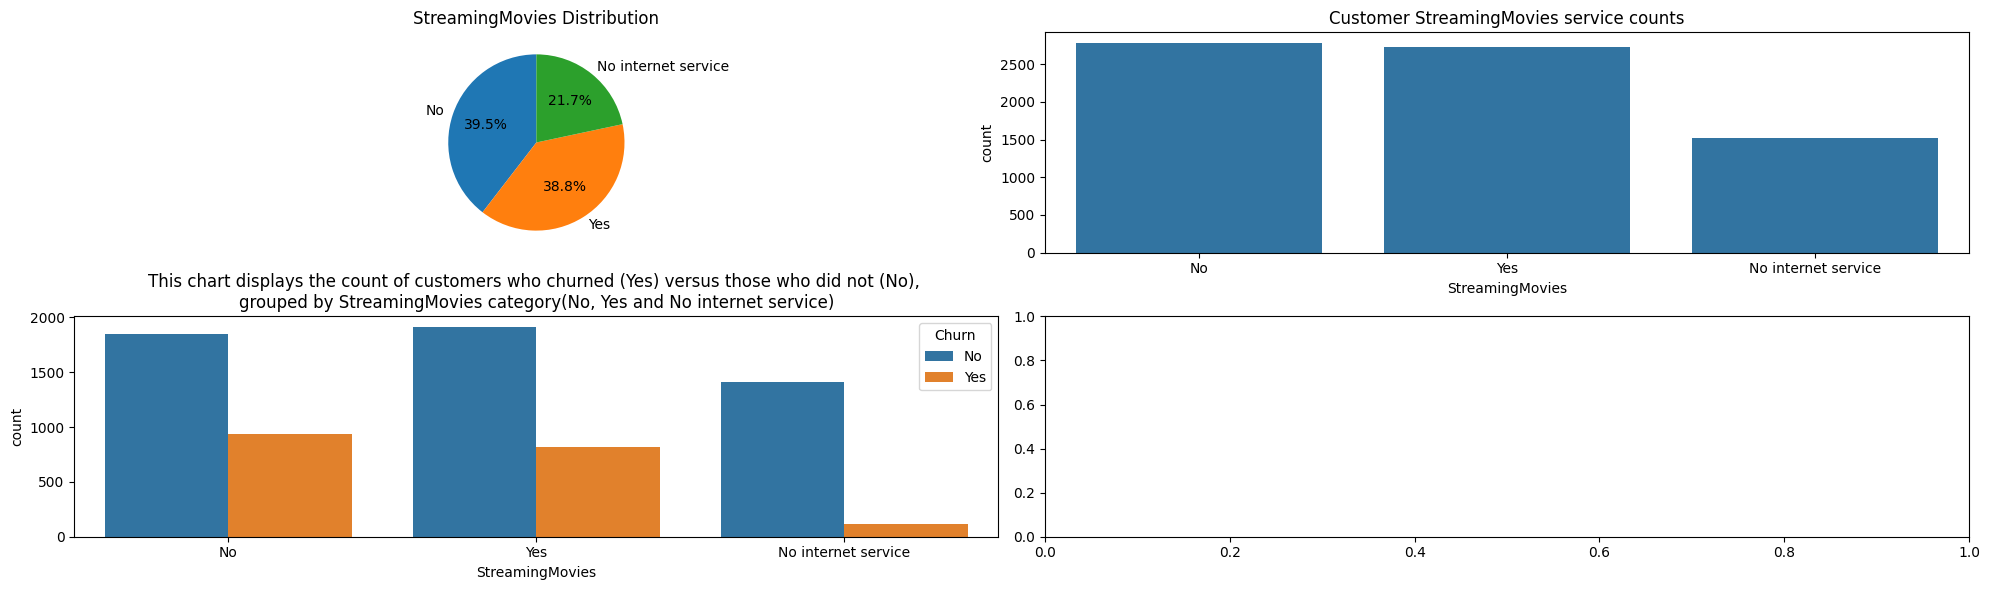

In [161]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['StreamingMovies'].value_counts(), 
    labels=features['StreamingMovies'].value_counts().index, 
    autopct='%1.1f%%', 
    startangle=90)
axes[0, 0].set_title('StreamingMovies Distribution')

sns.countplot(data=features, x='StreamingMovies', ax=axes[0, 1])
axes[0, 1].set_title('Customer StreamingMovies service counts')

sns.countplot(data=features, x='StreamingMovies', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) versus those who did not (No), \ngrouped by StreamingMovies category(No, Yes and No internet service)')

fig.tight_layout()
plt.show()

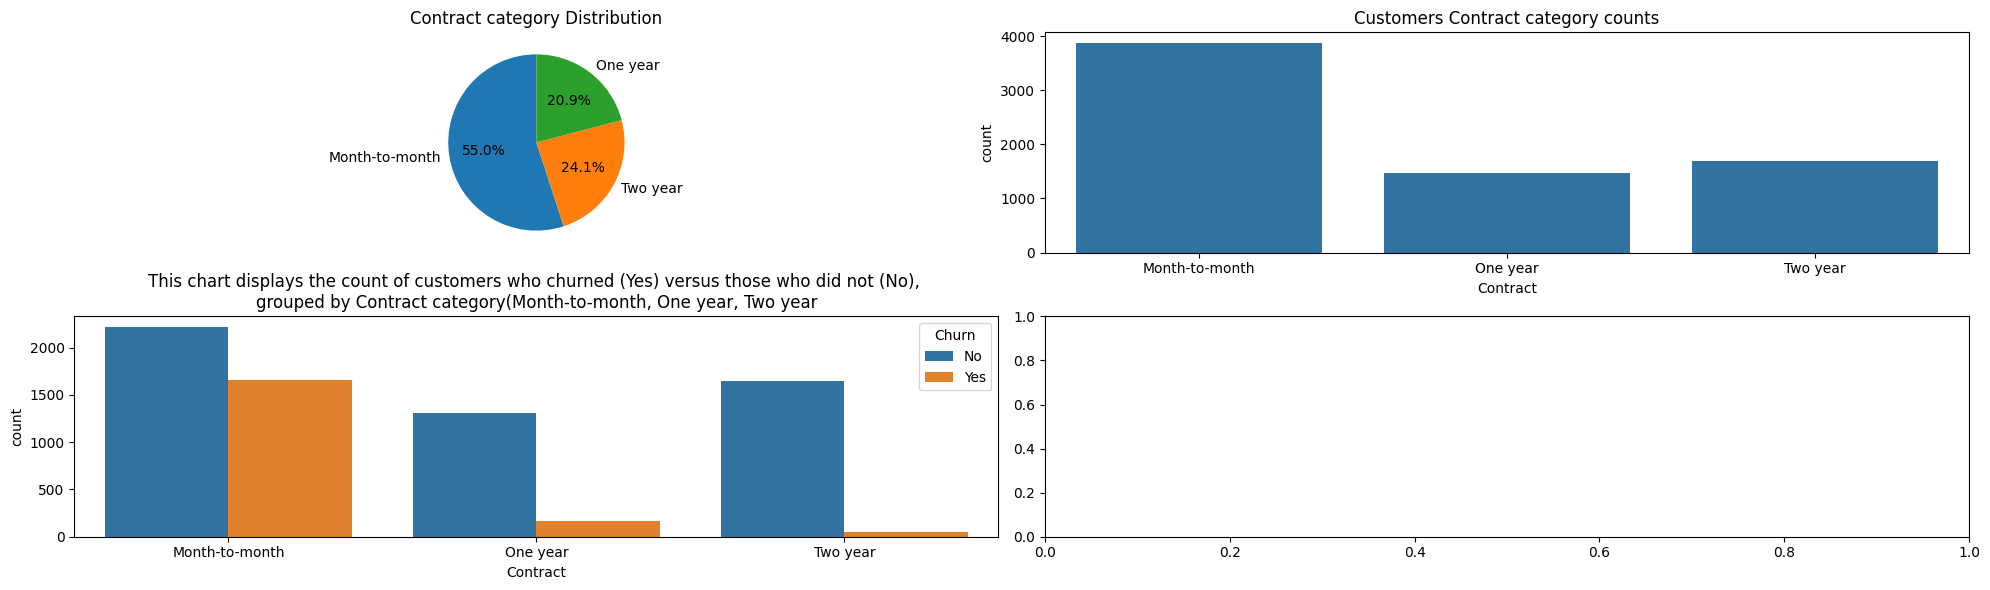

In [162]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['Contract'].value_counts(), 
    labels=features['Contract'].value_counts().index, 
    autopct='%1.1f%%', 
    startangle=90)
axes[0, 0].set_title('Contract category Distribution')

sns.countplot(data=features, x='Contract', ax=axes[0, 1])
axes[0, 1].set_title('Customers Contract category counts')

sns.countplot(data=features, x='Contract', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) versus those who did not (No), \ngrouped by Contract category(Month-to-month, One year, Two year')

fig.tight_layout()
plt.show()

From the above charts we can see that Contract has three categories like __One year__ which is `20.9%`, __Month-to-Month__ `55.0%` and __Two year__ which is `24.1%` of the customers

Compare cateogries with Churn or Not:
* __Month-to-month:__ Around 2000+ customers are not churned and around 1800+ customers are churned which is high churned rate among other categories.
* __One year:__ Around 1400+ customers are not churned and around 200-300 customers are churned
* __Two year:__ Around 1700+ customers are not churned in this contract category and very less customers are churned around 100 customers are churned.

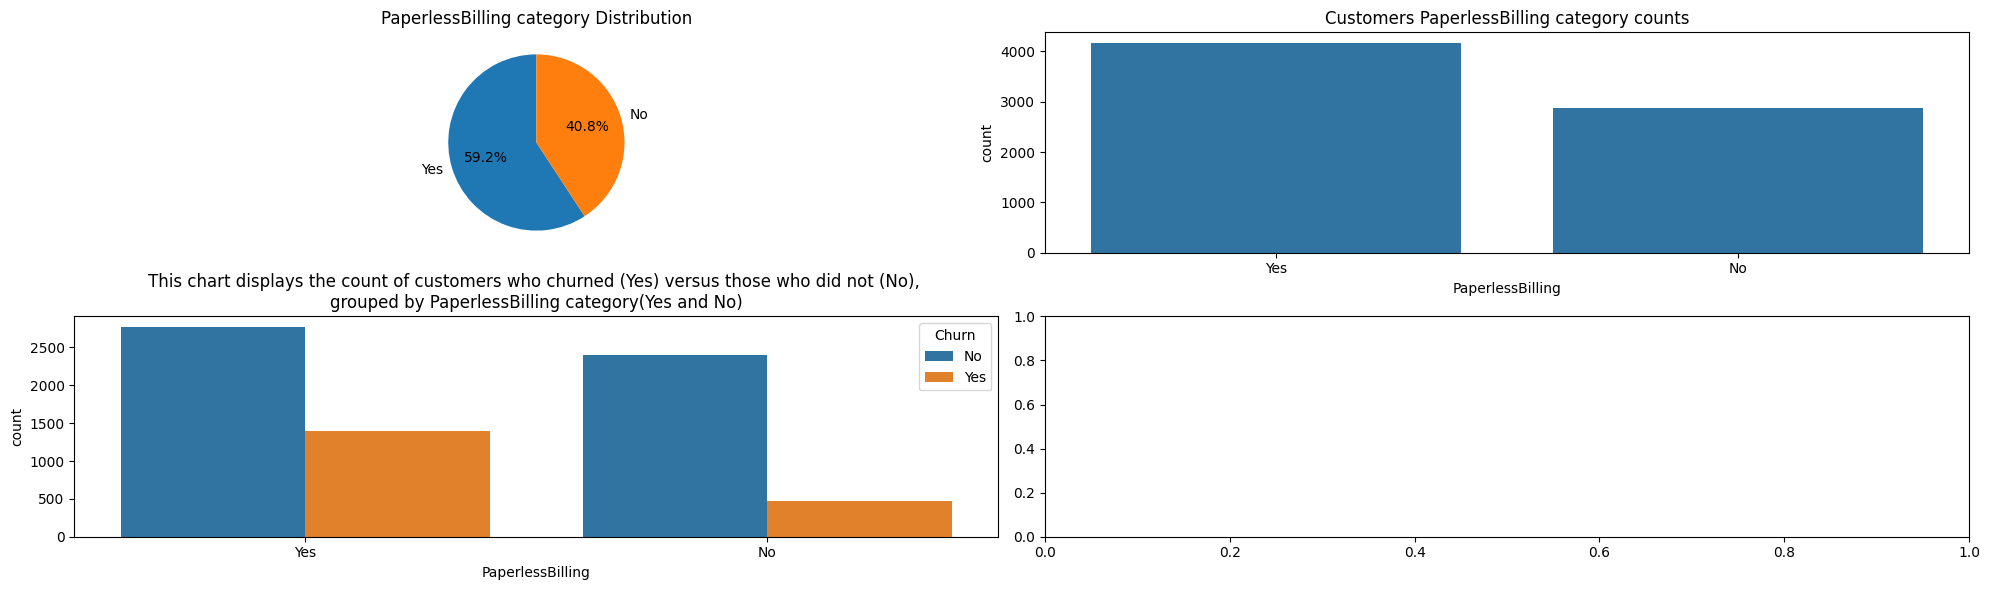

In [163]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['PaperlessBilling'].value_counts(), 
    labels=features['PaperlessBilling'].value_counts().index, 
    autopct='%1.1f%%', 
    startangle=90)
axes[0, 0].set_title('PaperlessBilling category Distribution')

sns.countplot(data=features, x='PaperlessBilling', ax=axes[0, 1])
axes[0, 1].set_title('Customers PaperlessBilling category counts')

sns.countplot(data=features, x='PaperlessBilling', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) versus those who did not (No), \ngrouped by PaperlessBilling category(Yes and No)')

fig.tight_layout()
plt.show()

There are `59.2%` of people use the PaperlessBilling and `40.8%` dont use it.

4171 customers around 2800 customer who are stayed and around 1400 customers who churned are using `PaperlessBilling` and total 2872 customers who not take the `PaperlessBilling` around 2300 customer are not churned and around 500 customers are churned.

`PaymentMethod` is customer payment method types

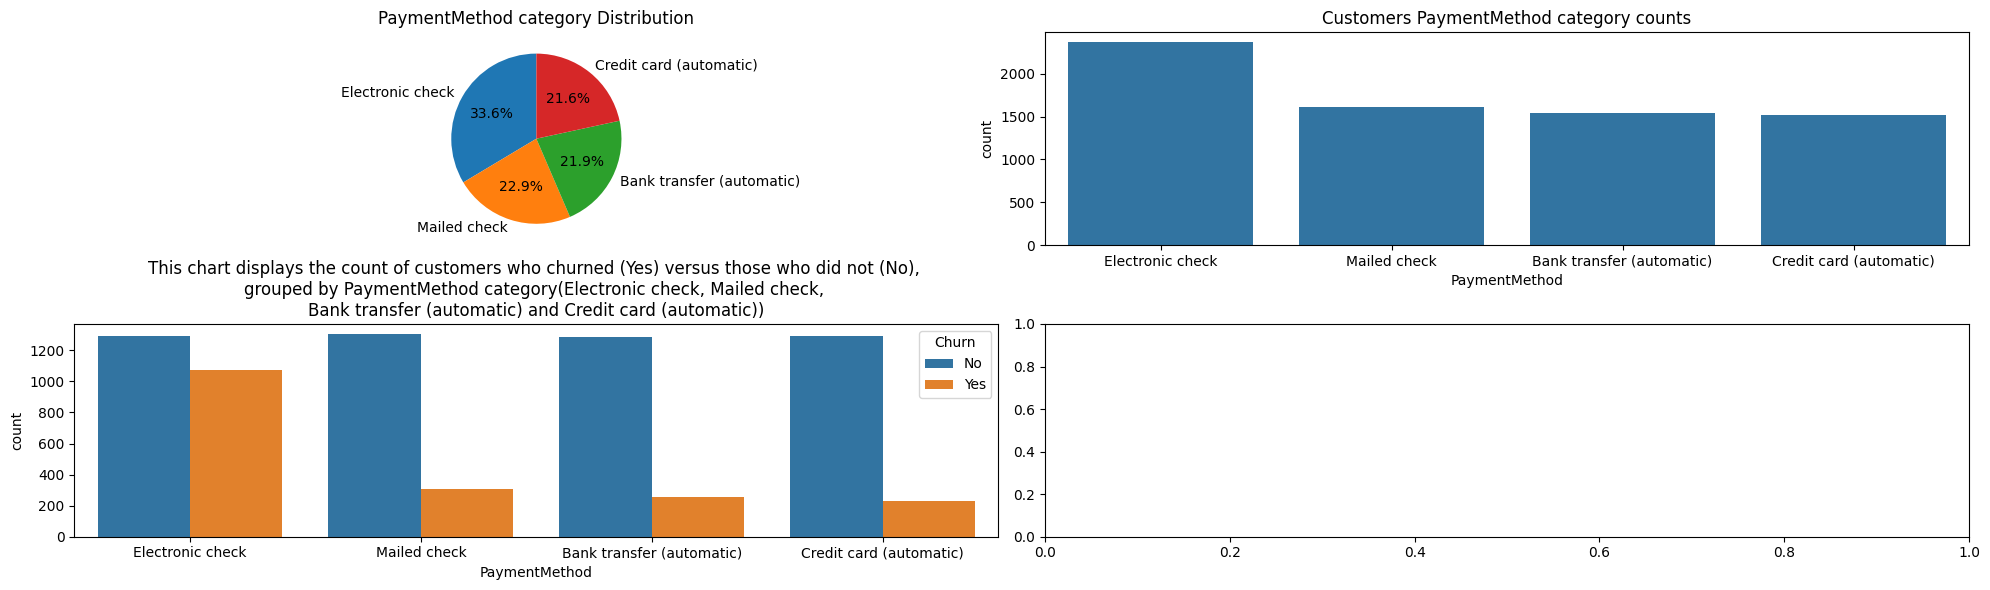

In [164]:
fig, axes = plt.subplots(2, 2, figsize=(20, 6))

axes[0, 0].pie(features['PaymentMethod'].value_counts(), 
    labels=features['PaymentMethod'].value_counts().index, 
    autopct='%1.1f%%', 
    startangle=90)
axes[0, 0].set_title('PaymentMethod category Distribution')

sns.countplot(data=features, x='PaymentMethod', ax=axes[0, 1])
axes[0, 1].set_title('Customers PaymentMethod category counts')

sns.countplot(data=features, x='PaymentMethod', hue=target, ax=axes[1, 0])
axes[1, 0].set_title('This chart displays the count of customers who churned (Yes) versus those who did not (No), \ngrouped by PaymentMethod category(Electronic check, Mailed check, \nBank transfer (automatic) and Credit card (automatic))')

fig.tight_layout()
plt.show()

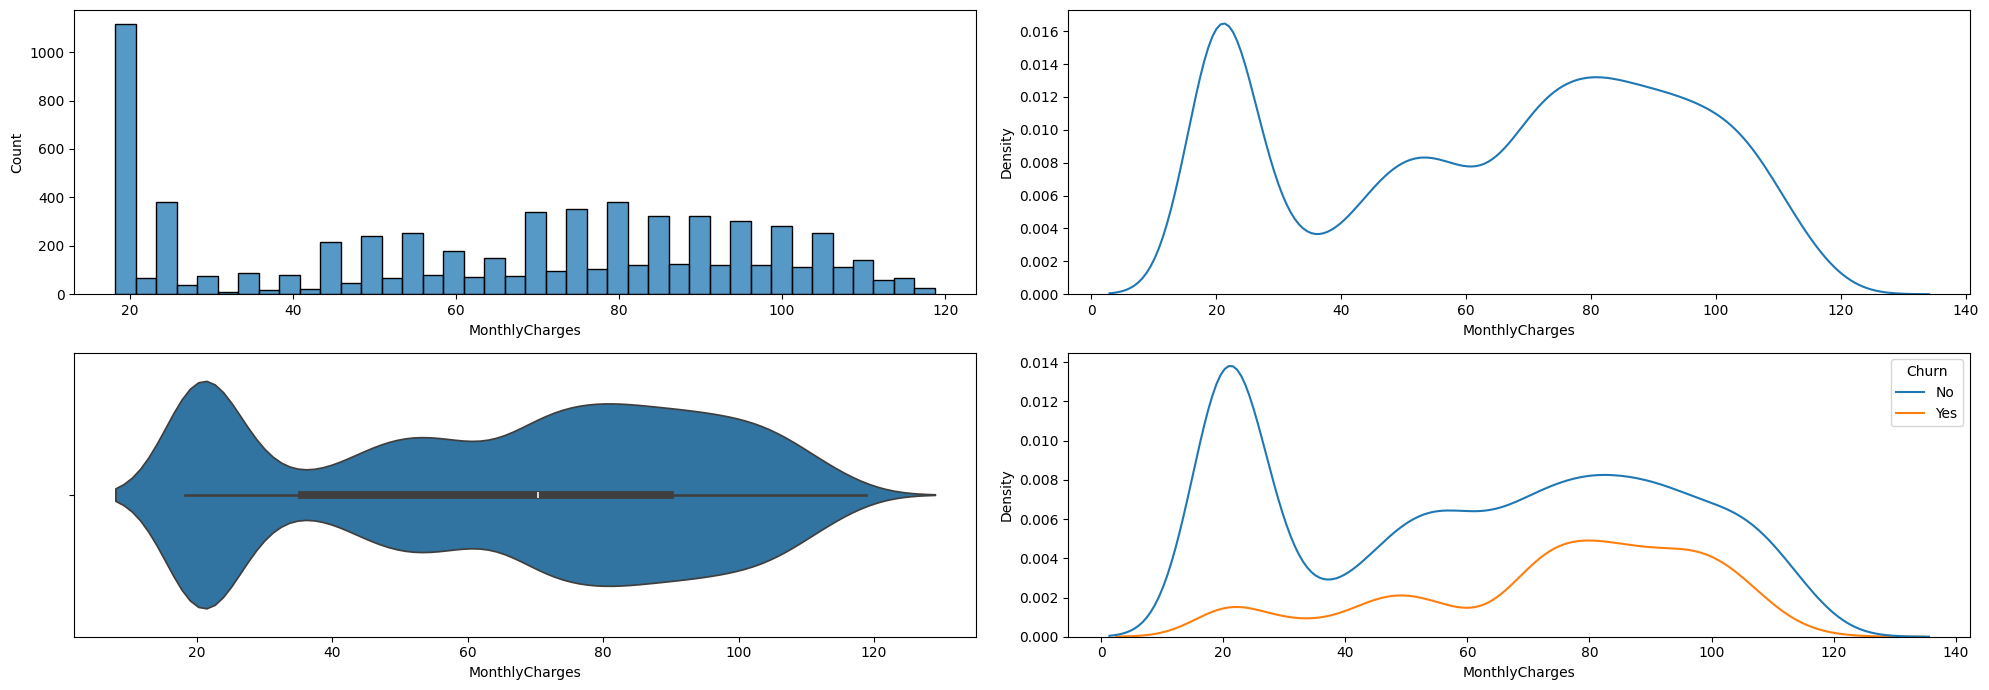

In [165]:
fig, axes = plt.subplots(2, 2, figsize=(20, 7))

sns.histplot(data=features, x='MonthlyCharges', bins=40, ax=axes[0, 0])
sns.kdeplot(data=features, x='MonthlyCharges', ax=axes[0, 1])
sns.violinplot(data=features, x='MonthlyCharges', ax=axes[1, 0])
sns.kdeplot(data=features, x='MonthlyCharges', hue=target, ax=axes[1, 1])

fig.tight_layout()
plt.show()

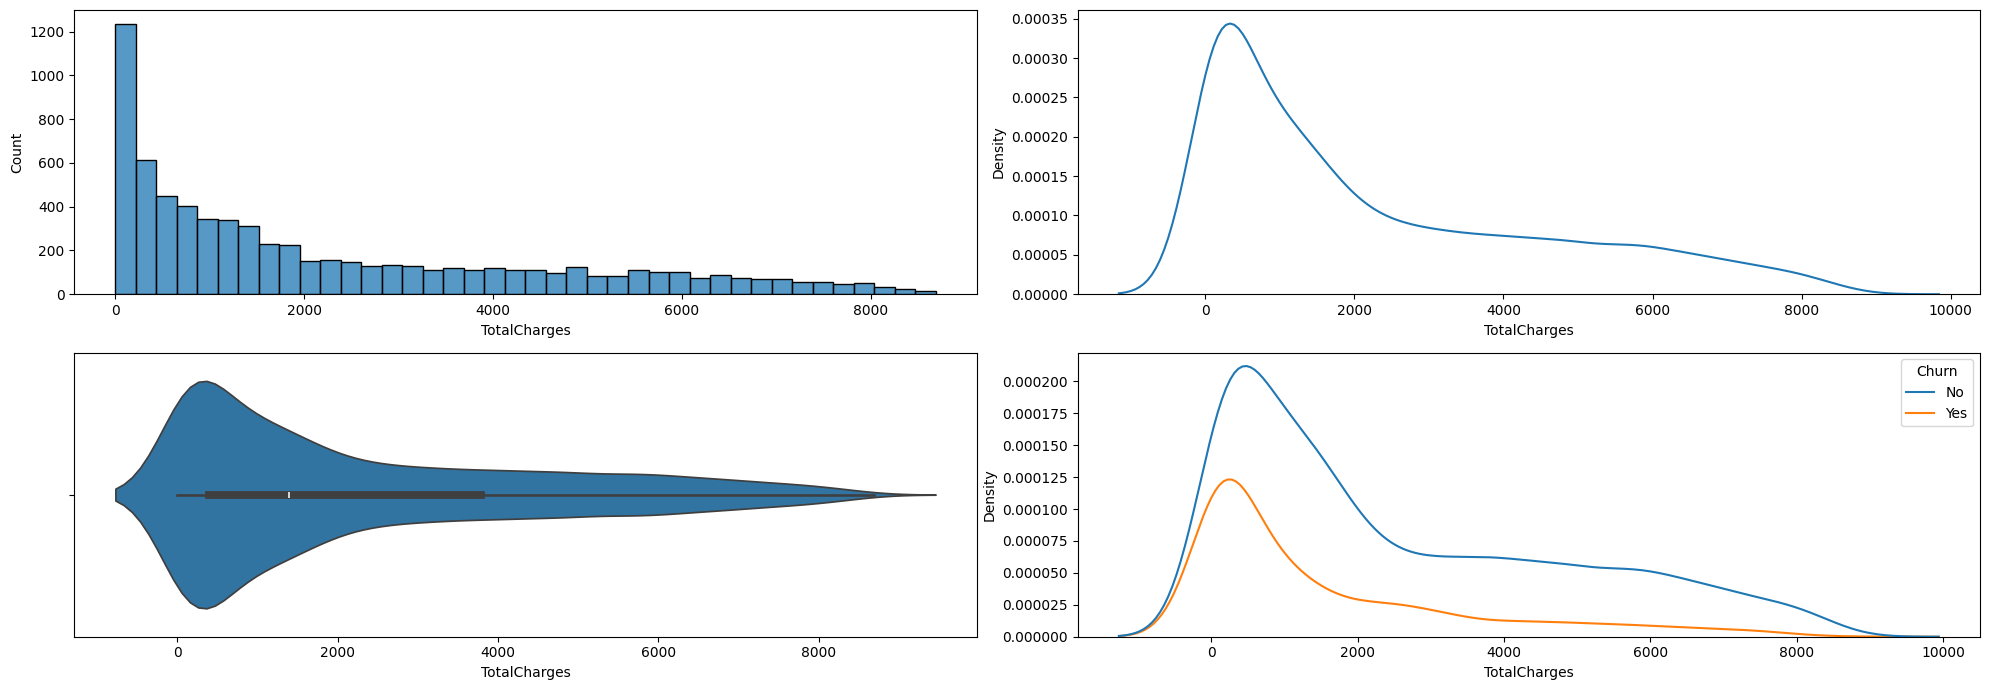

In [166]:
def convert_str_to_float(str_num: str):
    if str_num == ' ':
        return 0.0
    return float(str_num)

features['TotalCharges'] = features['TotalCharges'].apply(convert_str_to_float)

fig, axes = plt.subplots(2, 2, figsize=(20, 7))

sns.histplot(data=features, x='TotalCharges', bins=40, ax=axes[0, 0])
sns.kdeplot(data=features, x='TotalCharges', ax=axes[0, 1])
sns.violinplot(data=features, x='TotalCharges', ax=axes[1, 0])
sns.kdeplot(data=features, x='TotalCharges', hue=target, ax=axes[1, 1])

fig.tight_layout()
plt.show()

In [169]:
features.drop(columns=['SeniorCitizen']).describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


### Data preprocessing

<br><br>
__Separate the data based on their nature__

In [173]:
NUMERICAL_COLS = ('tenure', 'MonthlyCharges', 'TotalCharges')

NOMINAL_COLS = ('gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 
            'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 
            'PaymentMethod', )
ORDINAL_COLS = ('Contract', )

In [216]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

In [251]:

numerical_col_pipe = Pipeline(steps=[
    ('scaler', StandardScaler()),
])

nominal_col_pipe = Pipeline(steps=[
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first'))
])

ordinal_col_pipe = Pipeline(steps=[
    ('encoder', OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']]))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numerical_col', numerical_col_pipe, NUMERICAL_COLS),
        ('nominal_col', nominal_col_pipe, NOMINAL_COLS),
        ('ordinal_col', ordinal_col_pipe, ORDINAL_COLS)
    ]
)

preprocessor


,transformers,"[('numerical_col', ...), ('nominal_col', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


__Label encoder__

In [252]:
le = LabelEncoder()
le.classes_ = [{'No': 0, 'Yes': 1}]
targets = le.fit_transform(target)

__Split the data into `Train`, `Validation` and `Test` sets__

In [253]:
X = features
y = target

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, shuffle=True, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.3, shuffle=True, random_state=42, stratify=y_temp)

print(f'Train data features shape: {X_train.shape}')
print(f'Validation data features shape: {X_val.shape}')
print(f'Test data features shape: {X_test.shape}')

Train data features shape: (4225, 19)
Validation data features shape: (1972, 19)
Test data features shape: (846, 19)


In [291]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss

#### Logistic regression model

In [ ]:

lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=300, class_weight='balanced', random_state=0, solver=''))
])

lr_model

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical_col', ...), ('nominal_col', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
lr_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical_col', ...), ('nominal_col', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [257]:
train_prediction = lr_model.predict(X_train)

In [282]:
X_train.shape

len(X_train.iloc[50:60])

temp_x_train = X_train.iloc[50:60]
temp_y_train = y_train.iloc[50:60]

In [271]:
temp_x_train_preds = lr_model.predict_proba(temp_x_train)

In [290]:
print(f'Prediction probability of train data [50:60]\n\n{temp_x_train_preds}')

Prediction probability of train data [50:60]

[[0.70850707 0.29149293]
 [0.97290097 0.02709903]
 [0.9745667  0.0254333 ]
 [0.20955681 0.79044319]
 [0.76793021 0.23206979]
 [0.15120818 0.84879182]
 [0.52968507 0.47031493]
 [0.97273298 0.02726702]
 [0.96329053 0.03670947]
 [0.93159252 0.06840748]]


#### Find the loss for Logistic regression model

In [313]:
train_prob = lr_model.predict_proba(X_train)
train_loss = log_loss(y_train, train_prob)

val_prob = lr_model.predict_proba(X_val)
val_loss = log_loss(y_val, val_prob)

test_prob = lr_model.predict_proba(X_test)
test_loss = log_loss(y_test, test_prob)

print(f'Training Loss: {train_loss}')
print(f'Validation Loss: {val_loss}')
print(f'Test Loss: {test_loss}')

Training Loss: 0.4876640809035178
Validation Loss: 0.4820600344447109
Test Loss: 0.5324996621598872


In [296]:
lr_model_weights = lr_model['model'].coef_
lr_model_bias = lr_model['model'].intercept_

In [311]:
X_train_transformed = lr_model['preprocessor'].transform(X_train)

print(f'X_train_transformed: {X_train_transformed.shape}')

X_train_transformed: (4225, 29)


In [309]:
print(f'Model weights: {lr_model_weights.shape}')

Model weights: (1, 29)


#### Train model with Gradient Descent

In [ ]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def compute_gradient(X, y, w, b, reg_lambda):
    # Compute dJ/dW for logistic regression
    # reg_lambda corresponds to 1/C if we want L2 regularization of W.
    m = X.shape[0]
    z = np.matmul(X, w) + b
    p = sigmoid(z)
    error = p - z
    
    dw = np.matmul(X.T, error) / m + (reg_lambda / m) * w
    

np.float64(0.23260146804712467)